# Yang-Zhang Low-Volatility Basket Model

---

## Strategy Overview

| Parameter | Value |
|-----------|-------|
| **Universe** | 9 risk-on assets + 1 risk-off (TLT) |
| **Timeframe** | Daily (1D) |
| **Signal** | Rolling Yang-Zhang volatility (30-day window) |
| **Ranking** | **Lowest** YZ vol = highest rank (low-vol anomaly) |
| **Selection** | Bottom 3 assets by YZ vol ($\sigma_{YZ} < 30\%$) |
| **Risk-Off** | TLT (20Y Treasury ETF) — absorbs unused weight |
| **Rebalancing** | Biweekly (every 10 trading days) |
| **Allocation** | Vol-parity (inverse YZ vol weighted) |
| **Lookahead** | 1-day signal shift — signal on day $t$, trade on day $t+1$ |

### Strategy Logic

1. Compute a **rolling 30-day Yang-Zhang volatility** for each of the 9 risk-on assets
2. **Shift signals by 1 day** to prevent lookahead bias
3. Every 10 trading days, **rank** all assets by their lagged YZ vol
4. **Select bottom 3** with $\sigma_{YZ} < 30\%$ (calm, investable assets)
5. **Inverse-vol weight** the selected assets: $w_i = \frac{1/\sigma_i}{\sum 1/\sigma_j}$
6. If fewer than 3 qualify, allocate remaining weight to **TLT** (risk-off)
7. If none qualify (all vol > 30%), go **100% TLT**

### Why Low-Volatility Selection?

The **low-volatility anomaly** is one of the most robust findings in empirical finance:
- Low-vol assets deliver **higher risk-adjusted returns** than high-vol assets
- This was confirmed in Section 8 of the YZ notebook: **Low Vol regime had the highest Sharpe ratio**
- Yang-Zhang is the ideal estimator for this because it captures **overnight gaps** that close-to-close misses

### Asset Universe

| # | Ticker | Asset | Role |
|---|--------|-------|------|
| 1 | BTC-USD | Bitcoin | Risk-on |
| 2 | QQQ | Nasdaq 100 ETF | Risk-on |
| 3 | SPY | S&P 500 ETF | Risk-on |
| 4 | AAPL | Apple | Risk-on |
| 5 | TSLA | Tesla | Risk-on |
| 6 | GLD | Gold ETF | Risk-on |
| 7 | NVDA | NVIDIA | Risk-on |
| 8 | AMZN | Amazon | Risk-on |
| 9 | XLE | Energy Sector ETF | Risk-on |
| 10 | **TLT** | **20Y Treasury ETF** | **Risk-off** |

### Lookahead Bias Prevention

```
Day t-30 to t  : OHLC used to compute YZ_Vol[t]  (signal)
Day t          : YZ_Vol[t] is known at close
Day t+1        : signal is shifted → weights applied to return[t+1]
```

The 1-day shift ensures we **never trade on the same bar** that generated the signal.

In [1]:
# ============================================================
#  IMPORTS, CONFIGURATION & YANG-ZHANG FUNCTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})

# ── YANG-ZHANG VOLATILITY FUNCTION ───────────────────────────
def yang_zhang_vol(open_, high, low, close, window=30):
    """
    Yang-Zhang (2000) volatility estimator.
    Combines overnight, open-to-close, and Rogers-Satchell variances
    with optimal weighting. ~14x efficient AND drift-independent.
    Returns annualized volatility as a Series.
    """
    # Step 1: Overnight log-returns — ln(Open_t / Close_{t-1})
    log_oc = np.log(open_ / close.shift(1))
    # Step 2: Open-to-close log-returns — ln(Close_t / Open_t)
    log_co = np.log(close / open_)
    # Step 3-4: Rolling means
    log_oc_mean = log_oc.rolling(window).mean()
    log_co_mean = log_co.rolling(window).mean()
    # Step 5: Overnight variance
    overnight_var = ((log_oc - log_oc_mean) ** 2).rolling(window).sum() / (window - 1)
    # Step 6: Open-to-close variance
    openclose_var = ((log_co - log_co_mean) ** 2).rolling(window).sum() / (window - 1)
    # Step 7: Rogers-Satchell variance
    rs_var = (np.log(high/close) * np.log(high/open_) +
              np.log(low/close) * np.log(low/open_)).rolling(window).mean()
    # Step 8: Optimal k
    k = 0.34 / (1.34 + (window + 1) / (window - 1))
    # Step 9: Combine
    yz_var = overnight_var + k * openclose_var + (1 - k) * rs_var
    return np.sqrt(yz_var * 252)

# ── STRATEGY PARAMETERS ─────────────────────────────────────
ALL_TICKERS   = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA',
                 'GLD', 'NVDA', 'AMZN', 'XLE', 'TLT']
RISK_OFF      = 'TLT'
RISK_ON       = [t for t in ALL_TICKERS if t != RISK_OFF]

START_DATE    = '2018-01-01'
END_DATE      = '2025-01-01'
YZ_WINDOW     = 30           # 30-day rolling YZ vol
REBAL_PERIOD  = 10           # Biweekly
TOP_N         = 3            # Assets to hold
MAX_VOL       = 0.30         # 30% annualized — max vol to qualify
SIGNAL_LAG    = 1            # 1-day shift to prevent lookahead
INITIAL_CAP   = 100_000

print(f'Risk-on    : {len(RISK_ON)} assets — {RISK_ON}')
print(f'Risk-off   : {RISK_OFF}')
print(f'Period     : {START_DATE} to {END_DATE}')
print(f'YZ window  : {YZ_WINDOW}d | Rebalance: every {REBAL_PERIOD}d')
print(f'Signal lag : {SIGNAL_LAG}d (lookahead protection)')
print(f'Selection  : bottom {TOP_N} by YZ vol (< {MAX_VOL:.0%}), remainder -> {RISK_OFF}')
print(f'Weighting  : inverse-vol parity (1/σ_YZ)')

Risk-on    : 9 assets — ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
Risk-off   : TLT
Period     : 2018-01-01 to 2025-01-01
YZ window  : 30d | Rebalance: every 10d
Signal lag : 1d (lookahead protection)
Selection  : bottom 3 by YZ vol (< 30%), remainder -> TLT
Weighting  : inverse-vol parity (1/σ_YZ)


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


## 1. Data Download

In [2]:
# ============================================================
#  DOWNLOAD DAILY OHLC PRICES (Yang-Zhang needs O, H, L, C)
# ============================================================

ohlc = {}  # dict of DataFrames, one per ticker
for ticker in ALL_TICKERS:
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     progress=False, auto_adjust=True)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    if len(df) > 0:
        ohlc[ticker] = df[['Open', 'High', 'Low', 'Close']]

# Build aligned close-price panel and returns
close_prices = pd.DataFrame({t: ohlc[t]['Close'] for t in ALL_TICKERS})
close_prices = close_prices.ffill().dropna()
returns = close_prices.pct_change().dropna()

print(f'Date range  : {close_prices.index[0].date()} to {close_prices.index[-1].date()}')
print(f'Trading days: {len(close_prices)}\n')
for t in close_prices.columns:
    role = 'RISK-OFF' if t == RISK_OFF else 'risk-on'
    pct = (close_prices[t].iloc[-1] / close_prices[t].iloc[0] - 1) * 100
    print(f'  {t:>8} [{role:>8}] | {close_prices[t].iloc[0]:>10,.2f} -> {close_prices[t].iloc[-1]:>10,.2f} | {pct:>+8.1f}%')

Date range  : 2018-01-02 to 2024-12-31
Trading days: 2556

   BTC-USD [ risk-on] |  14,982.10 ->  93,429.20 |   +523.6%
       QQQ [ risk-on] |     150.41 ->     508.65 |   +238.2%
       SPY [ risk-on] |     237.21 ->     579.28 |   +144.2%
      AAPL [ risk-on] |      40.30 ->     249.06 |   +517.9%
      TSLA [ risk-on] |      21.37 ->     403.84 |  +1789.9%
       GLD [ risk-on] |     125.15 ->     242.13 |    +93.5%
      NVDA [ risk-on] |       4.93 ->     134.25 |  +2624.0%
      AMZN [ risk-on] |      59.45 ->     219.39 |   +269.0%
       XLE [ risk-on] |      25.92 ->      41.45 |    +59.9%
       TLT [RISK-OFF] |      99.86 ->      83.01 |    -16.9%


### Normalized Price Chart

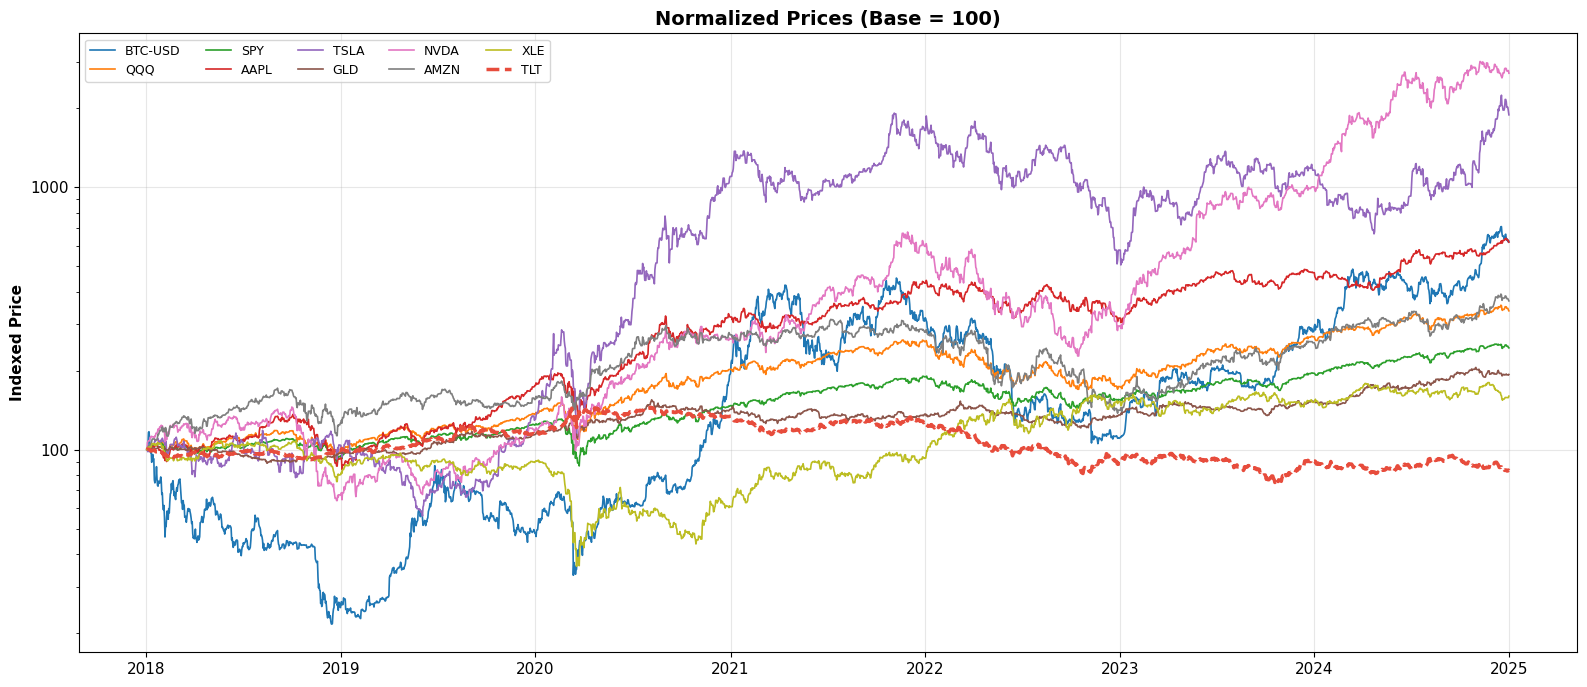

In [3]:
norm = close_prices / close_prices.iloc[0] * 100
fig, ax = plt.subplots(figsize=(16, 7))
for col in norm.columns:
    style = {'linewidth': 2.5, 'linestyle': '--', 'color': '#e74c3c'} if col == RISK_OFF else {'linewidth': 1.2}
    ax.plot(norm.index, norm[col], label=col, **style)
ax.set_title('Normalized Prices (Base = 100)', fontsize=14)
ax.set_ylabel('Indexed Price'); ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}'))
ax.legend(ncol=5, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 2. Rolling Yang-Zhang Volatility

Computed for **risk-on assets only** (9 assets). TLT is excluded from ranking — it serves purely as the risk-off destination.

**Key**: after computing, we **shift the signal by 1 day** so that YZ vol computed from OHLC data up to day $t$ is only used for trading on day $t+1$.

Unlike the Hurst model which ranks by **highest** persistence, here we rank by **lowest** vol — exploiting the low-volatility anomaly.

In [4]:
# ============================================================
#  COMPUTE ROLLING YANG-ZHANG VOL FOR ALL RISK-ON ASSETS
# ============================================================

yz_raw = pd.DataFrame(index=close_prices.index)

for ticker in RISK_ON:
    df = ohlc[ticker].reindex(close_prices.index).ffill().dropna()
    yz_raw[ticker] = yang_zhang_vol(
        df['Open'], df['High'], df['Low'], df['Close'], YZ_WINDOW
    )

# ── CRITICAL: Shift signal by SIGNAL_LAG days to prevent lookahead ──
# YZ_Vol[t] uses OHLC[t-30 : t], known at close of day t.
# Shifting by 1 means we only act on it from day t+1 onward.
yz_df = yz_raw.shift(SIGNAL_LAG)
yz_df = yz_df.dropna(how='all')

print(f'Done: {len(yz_df)} obs x {len(yz_df.columns)} assets')
print(f'Signal lag : {SIGNAL_LAG} day(s) applied')
print(f'\nLatest YZ Vol (ranked lowest-first, after lag):')
latest = yz_df.iloc[-1].sort_values(ascending=True)
for t, v in latest.items():
    marker = '  ✓' if v < MAX_VOL else '  ✗ (too volatile)'
    print(f'  {t:>8}: {v:.1%}{marker}')

Done: 2496 obs x 9 assets
Signal lag : 1 day(s) applied

Latest YZ Vol (ranked lowest-first, after lag):
       GLD: 10.7%  ✓
       SPY: 14.6%  ✓
       XLE: 17.8%  ✓
       QQQ: 18.5%  ✓
      AAPL: 21.2%  ✓
      AMZN: 28.8%  ✓
      NVDA: 46.1%  ✗ (too volatile)
   BTC-USD: 47.7%  ✗ (too volatile)
      TSLA: 68.4%  ✗ (too volatile)


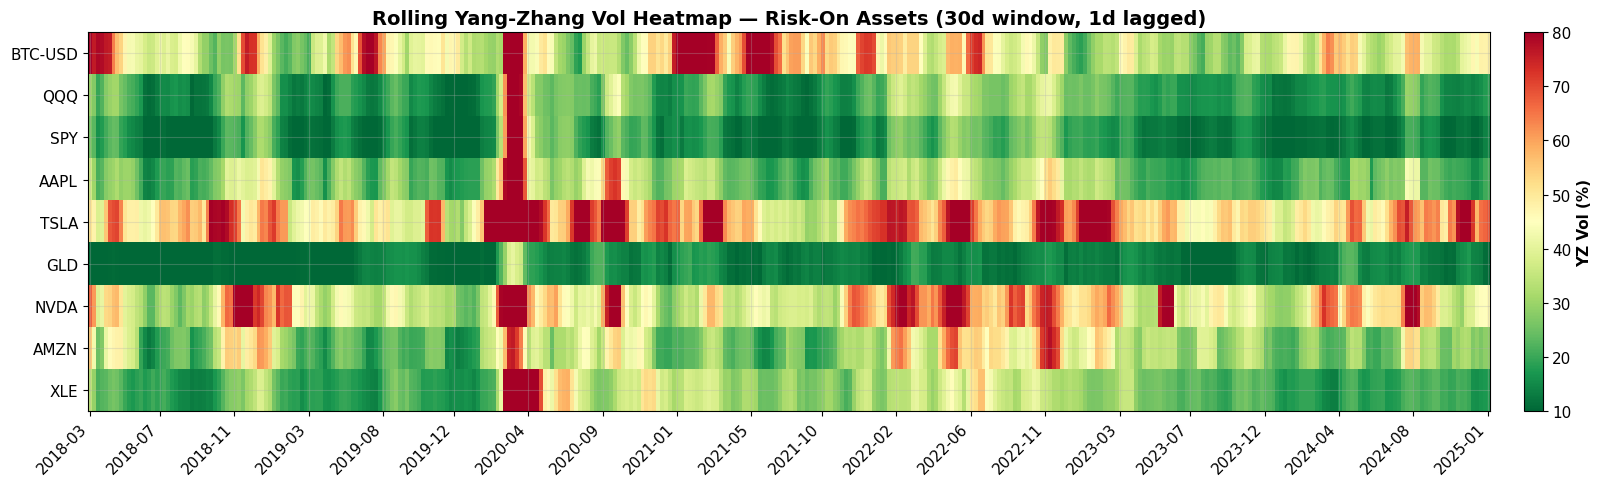

In [5]:
# ============================================================
#  ROLLING YZ VOL HEATMAP (lower = greener = preferred)
# ============================================================

hw = yz_df.resample('W').last().dropna(how='all')
fig, ax = plt.subplots(figsize=(18, 5))
im = ax.imshow(hw.T.values * 100, aspect='auto', cmap='RdYlGn_r',
               vmin=10, vmax=80, interpolation='nearest')
ax.set_yticks(range(len(hw.columns))); ax.set_yticklabels(hw.columns)
ti = np.linspace(0, len(hw)-1, 20, dtype=int)
ax.set_xticks(ti)
ax.set_xticklabels([hw.index[i].strftime('%Y-%m') for i in ti], rotation=45, ha='right')
plt.colorbar(im, ax=ax, pad=0.02).set_label('YZ Vol (%)')
ax.set_title('Rolling Yang-Zhang Vol Heatmap — Risk-On Assets (30d window, 1d lagged)',
             fontsize=14)
plt.tight_layout(); plt.show()

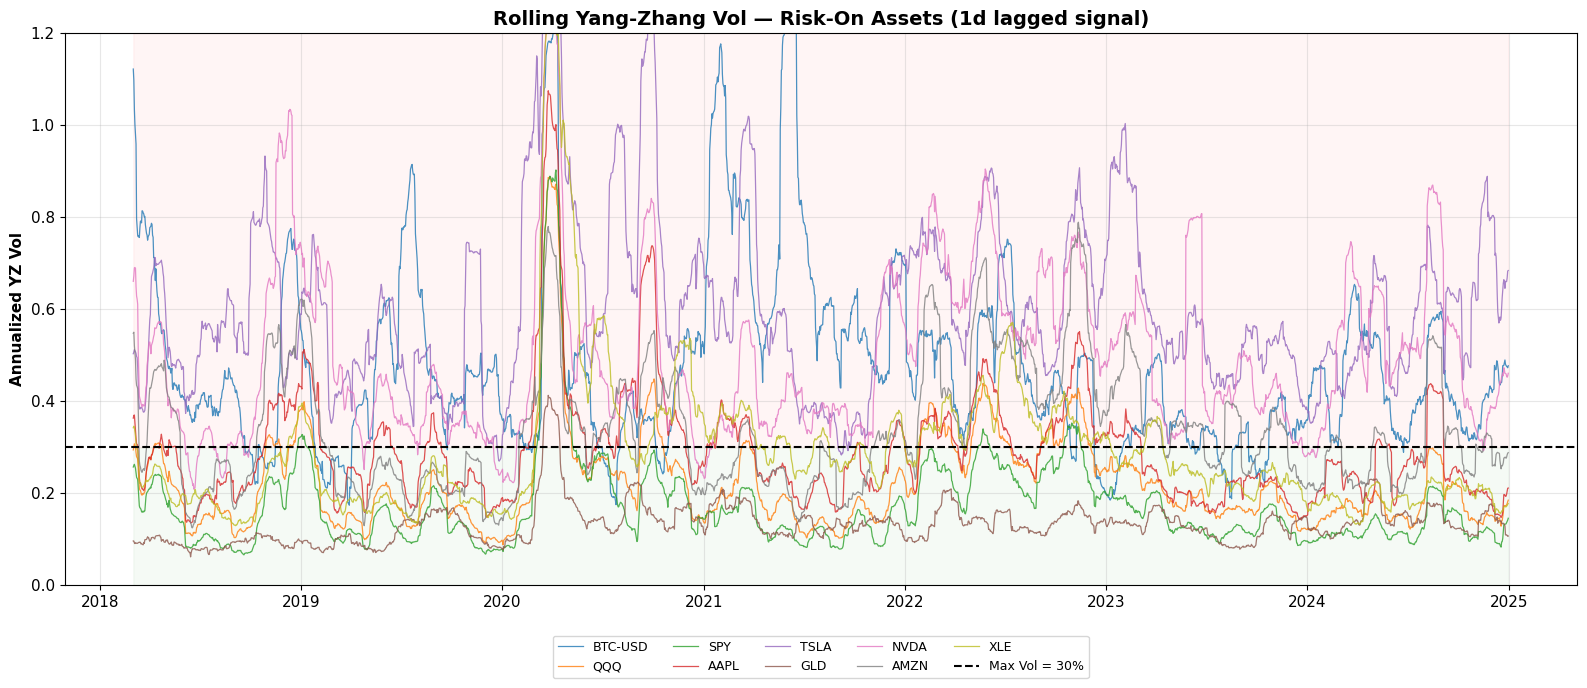

In [6]:
# ============================================================
#  ROLLING YZ VOL LINE CHART
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))
for col in yz_df.columns:
    ax.plot(yz_df.index, yz_df[col], lw=0.9, alpha=0.8, label=col)
ax.axhline(MAX_VOL, color='black', lw=1.5, ls='--', label=f'Max Vol = {MAX_VOL:.0%}')
ax.fill_between(yz_df.index, 0, MAX_VOL, alpha=0.04, color='green')
ax.fill_between(yz_df.index, MAX_VOL, 1.5, alpha=0.04, color='red')
ax.set_ylim(0, 1.2); ax.set_ylabel('Annualized YZ Vol')
ax.set_title('Rolling Yang-Zhang Vol — Risk-On Assets (1d lagged signal)', fontsize=14)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

## 3. Backtest Engine

**No data leakage**: YZ vol signals are already shifted by 1 day. On any day, the backtest only sees yesterday's YZ vol.

**Inverse-vol weighting**: Instead of equal weight, each selected asset gets weight proportional to $1/\sigma_{YZ}$. Calmer assets get more capital — this is **volatility parity**.

| Scenario | Risk-On Weight | TLT Weight |
|----------|---------------|------------|
| 3 assets qualify (vol < 30%) | 100% (vol-parity) | 0% |
| 2 assets qualify | ~67% (vol-parity) | ~33% |
| 1 asset qualifies | ~33% | ~67% |
| 0 assets qualify | 0% | **100%** |

In [7]:
# ============================================================
#  BACKTEST ENGINE (LOW-VOL SELECTION + VOL-PARITY + TLT RISK-OFF)
# ============================================================

def run_backtest(returns_df, yz_vol_df, risk_off_ticker,
                 top_n, rebal_period, max_vol):
    """
    Yang-Zhang low-vol basket backtest with risk-off asset.
    yz_vol_df is ALREADY lagged — no additional shift needed.
    Selects LOWEST vol assets and weights by inverse vol (vol-parity).
    """
    common_idx = returns_df.index.intersection(yz_vol_df.index)
    ret = returns_df.loc[common_idx]
    yz  = yz_vol_df.loc[common_idx]

    all_assets = list(ret.columns)
    n_days = len(ret)

    # Pre-allocate arrays
    port_ret_arr = np.zeros(n_days)
    weight_arr = np.zeros((n_days, len(all_assets)))
    asset_idx = {a: i for i, a in enumerate(all_assets)}
    rebal_log = []

    # Start fully in risk-off
    cur_w = np.zeros(len(all_assets))
    cur_w[asset_idx[risk_off_ticker]] = 1.0
    days_since = rebal_period  # Force first rebalance

    ret_vals = ret.values

    for i in range(n_days):
        days_since += 1
        date = ret.index[i]

        if days_since >= rebal_period:
            vol_vals = yz.iloc[i].dropna()

            # Select assets with vol below threshold, sorted LOWEST first
            calm = vol_vals[vol_vals < max_vol].sort_values(ascending=True)
            selected = calm.head(top_n)
            n_sel = len(selected)

            # Reset weights
            cur_w[:] = 0.0

            if n_sel > 0:
                # Inverse-vol weighting (vol parity)
                inv_vol = 1.0 / selected.values                # 1/σ for each
                raw_weights = inv_vol / inv_vol.sum()           # normalize to sum=1
                # Scale down if fewer than top_n qualify
                scale = n_sel / top_n                           # e.g., 2/3 if only 2 qualify
                for j, ticker in enumerate(selected.index):
                    cur_w[asset_idx[ticker]] = raw_weights[j] * scale

            # Remaining weight -> TLT
            risk_off_w = 1.0 - cur_w.sum()
            cur_w[asset_idx[risk_off_ticker]] += risk_off_w

            rebal_log.append({
                'date': date,
                'selected': list(selected.index),
                'yz_vols': selected.to_dict(),
                'weights': {t: cur_w[asset_idx[t]] for t in selected.index},
                'n_selected': n_sel,
                'tlt_weight': cur_w[asset_idx[risk_off_ticker]],
            })
            days_since = 0

        # Daily return = dot product of weights and returns
        port_ret_arr[i] = np.dot(cur_w, ret_vals[i])
        weight_arr[i] = cur_w.copy()

    port_ret = pd.Series(port_ret_arr, index=ret.index)
    weights = pd.DataFrame(weight_arr, index=ret.index, columns=all_assets)

    return port_ret, weights, rebal_log


# ── Run the backtest ──────────────────────────────────────────────────
port_ret, holdings, rebal_log = run_backtest(
    returns, yz_df, RISK_OFF, TOP_N, REBAL_PERIOD, MAX_VOL
)

equity = (1 + port_ret).cumprod() * INITIAL_CAP
spy_ret = returns['SPY'].reindex(port_ret.index).fillna(0)
spy_equity = (1 + spy_ret).cumprod() * INITIAL_CAP

# Risk-off allocation stats
tlt_weights = [r['tlt_weight'] for r in rebal_log]
pct_full_riskon  = sum(1 for w in tlt_weights if w < 0.01) / len(tlt_weights) * 100
pct_full_riskoff = sum(1 for w in tlt_weights if w >= 0.99) / len(tlt_weights) * 100

print(f'Backtest complete: {len(rebal_log)} rebalances')
print(f'\nFinal equity: ${equity.iloc[-1]:,.0f}  |  SPY B&H: ${spy_equity.iloc[-1]:,.0f}')
print(f'\nRisk-off stats:')
print(f'  Avg TLT weight : {np.mean(tlt_weights):.1%}')
print(f'  Fully risk-on  : {pct_full_riskon:.1f}% of rebalances')
print(f'  Fully risk-off : {pct_full_riskoff:.1f}% of rebalances (100% TLT)')

Backtest complete: 250 rebalances

Final equity: $255,956  |  SPY B&H: $243,925

Risk-off stats:
  Avg TLT weight : 6.9%
  Fully risk-on  : 85.6% of rebalances
  Fully risk-off : 1.2% of rebalances (100% TLT)


## 4. Performance — YZ Low-Vol Strategy vs SPY Buy & Hold

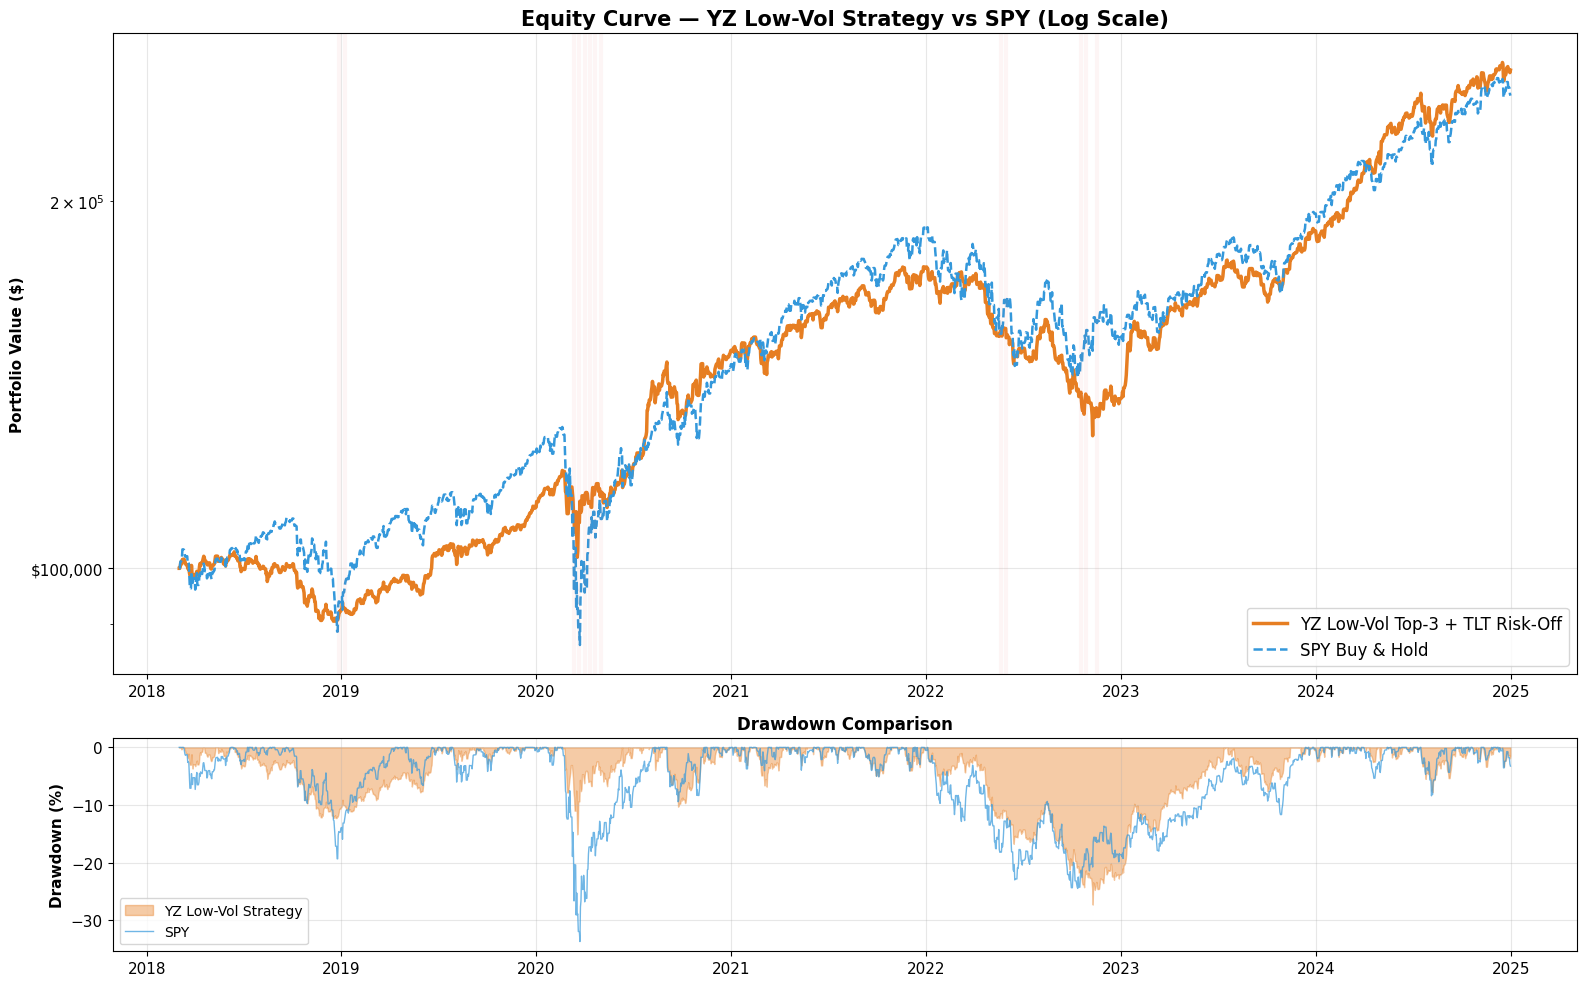

In [8]:
# ============================================================
#  EQUITY CURVE (LOG SCALE) + DRAWDOWN
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10),
                                gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(equity.index, equity, color='#e67e22', lw=2.5,
         label=f'YZ Low-Vol Top-{TOP_N} + TLT Risk-Off')
ax1.plot(spy_equity.index, spy_equity, color='#3498db', lw=1.8,
         linestyle='--', label='SPY Buy & Hold')

# Shade heavy risk-off periods (TLT weight > 50%)
for r in rebal_log:
    if r['tlt_weight'] > 0.5:
        ax1.axvline(r['date'], color='#e74c3c', alpha=0.05, lw=3)

ax1.set_yscale('log')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'${y:,.0f}'))
ax1.set_title('Equity Curve — YZ Low-Vol Strategy vs SPY (Log Scale)', fontsize=15)
ax1.set_ylabel('Portfolio Value ($)')
ax1.legend(fontsize=12)

# Drawdown comparison
dd_strat = (equity / equity.cummax() - 1) * 100
dd_spy   = (spy_equity / spy_equity.cummax() - 1) * 100
ax2.fill_between(dd_strat.index, dd_strat, 0, color='#e67e22', alpha=0.4,
                 label='YZ Low-Vol Strategy')
ax2.plot(dd_spy.index, dd_spy, color='#3498db', lw=1, alpha=0.7, label='SPY')
ax2.set_ylabel('Drawdown (%)'); ax2.set_title('Drawdown Comparison', fontsize=12)
ax2.legend(fontsize=10)

plt.tight_layout(); plt.show()

In [9]:
# ============================================================
#  PERFORMANCE METRICS TABLE
# ============================================================

def calc_metrics(ret_s, name, rf=0.04):
    """Compute standard performance metrics from a return series."""
    r = ret_s.dropna(); n = len(r)
    eq = (1 + r).cumprod(); yrs = n / 252
    tot = eq.iloc[-1] - 1
    cagr = (1 + tot) ** (1 / yrs) - 1
    vol = r.std() * np.sqrt(252)
    rfd = (1 + rf) ** (1/252) - 1                        # daily risk-free rate
    sharpe = (r.mean() - rfd) / r.std() * np.sqrt(252) if r.std() > 0 else 0
    ds = r[r < 0].std() * np.sqrt(252)                   # downside deviation
    sortino = (cagr - rf) / ds if ds > 0 else 0
    dd = eq / eq.cummax() - 1; mdd = dd.min()
    calmar = cagr / abs(mdd) if abs(mdd) > 0 else 0
    wr = (r > 0).mean()                                  # win rate
    g = r[r > 0].sum(); l = abs(r[r < 0].sum())          # total gains/losses
    pf = g / l if l > 0 else float('inf')                # profit factor
    return {'Strategy': name, 'CAGR': f'{cagr:.1%}', 'Vol': f'{vol:.1%}',
            'Sharpe': f'{sharpe:.2f}', 'Sortino': f'{sortino:.2f}',
            'Max DD': f'{mdd:.1%}', 'Calmar': f'{calmar:.2f}',
            'Win Rate': f'{wr:.1%}', 'Profit Factor': f'{pf:.2f}',
            'Total Return': f'{tot:.1%}'}

metrics = pd.DataFrame([
    calc_metrics(port_ret, f'YZ Low-Vol Top-{TOP_N} + TLT'),
    calc_metrics(spy_ret, 'SPY Buy & Hold'),
]).set_index('Strategy')

print('\n' + '='*85)
print('PERFORMANCE COMPARISON')
print('='*85)
print(metrics.to_string())


PERFORMANCE COMPARISON
                         CAGR    Vol Sharpe Sortino  Max DD Calmar Win Rate Profit Factor Total Return
Strategy                                                                                              
YZ Low-Vol Top-3 + TLT  10.0%  10.7%   0.57    0.64  -27.3%   0.36    39.6%          1.22       156.0%
SPY Buy & Hold           9.4%  16.1%   0.40    0.34  -33.7%   0.28    37.9%          1.16       143.9%


## 5. Holdings & Allocation Analysis

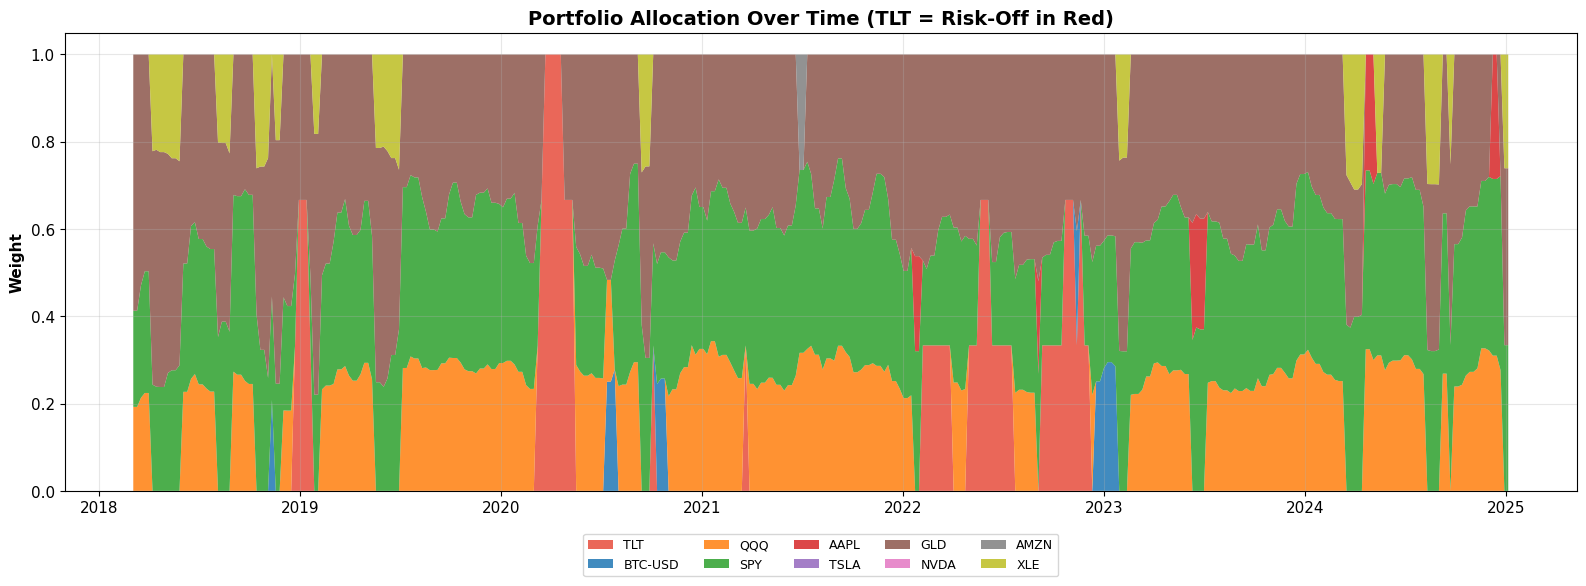

In [10]:
# ============================================================
#  HOLDINGS STACKED AREA (TLT HIGHLIGHTED IN RED)
# ============================================================

wk = holdings.resample('W').last().dropna(how='all').fillna(0)
# Put TLT first so it's at the bottom of the stack (most visible)
cols = [RISK_OFF] + [c for c in wk.columns if c != RISK_OFF]
wk = wk[cols]

fig, ax = plt.subplots(figsize=(16, 6))
colors = ['#e74c3c'] + [plt.cm.tab10(i) for i in range(len(cols)-1)]
ax.stackplot(wk.index, [wk[c] for c in wk.columns],
             labels=wk.columns, colors=colors, alpha=0.85)
ax.set_title('Portfolio Allocation Over Time (TLT = Risk-Off in Red)', fontsize=14)
ax.set_ylabel('Weight'); ax.set_ylim(0, 1.05)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

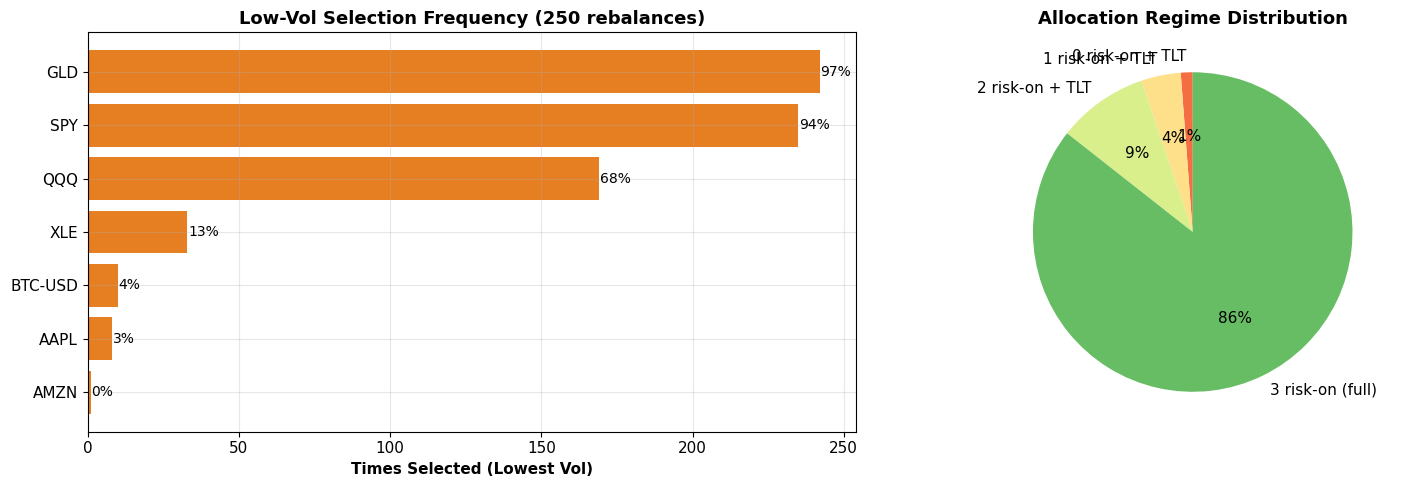

TLT held (any weight) in 72/250 rebalances (29%)

Note: GLD and SPY appear frequently — they are consistently the lowest-vol assets.


In [11]:
# ============================================================
#  SELECTION FREQUENCY + RISK-OFF ALLOCATION
# ============================================================

all_sel = [t for r in rebal_log for t in r['selected']]
freq = Counter(all_sel)
total = len(rebal_log)
tlt_times = sum(1 for r in rebal_log if r['tlt_weight'] > 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Left: selection frequency bar chart
tickers_sorted = [t for t, _ in freq.most_common()]
counts_sorted  = [c for _, c in freq.most_common()]
ax1.barh(tickers_sorted, counts_sorted, color='#e67e22')
ax1.set_xlabel('Times Selected (Lowest Vol)')
ax1.set_title(f'Low-Vol Selection Frequency ({total} rebalances)', fontsize=13)
ax1.invert_yaxis()
for i, (t, c) in enumerate(zip(tickers_sorted, counts_sorted)):
    ax1.text(c + 0.3, i, f'{c/total:.0%}', va='center', fontsize=10)

# Right: allocation regime pie chart
n_counts = Counter(r['n_selected'] for r in rebal_log)
labels = [f'{n} risk-on + TLT' if n < TOP_N else f'{n} risk-on (full)'
          for n in sorted(n_counts.keys())]
sizes = [n_counts[n] for n in sorted(n_counts.keys())]
ax2.pie(sizes, labels=labels, autopct='%1.0f%%', startangle=90,
        colors=plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(sizes))))
ax2.set_title('Allocation Regime Distribution', fontsize=13)

plt.tight_layout(); plt.show()
print(f'TLT held (any weight) in {tlt_times}/{total} rebalances ({tlt_times/total:.0%})')
print(f'\nNote: GLD and SPY appear frequently — they are consistently the lowest-vol assets.')

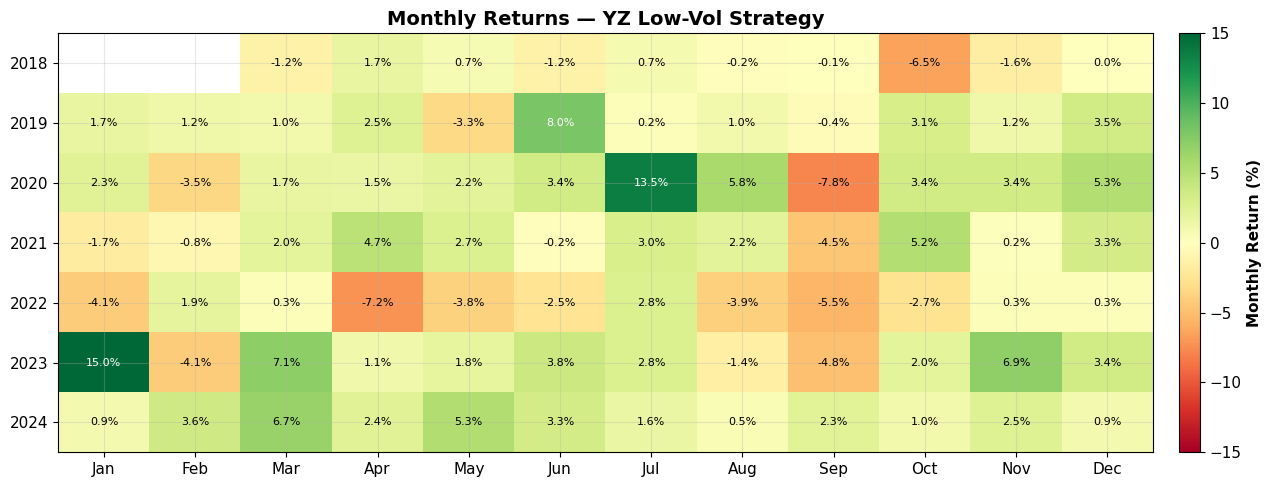

In [12]:
# ============================================================
#  MONTHLY RETURNS HEATMAP
# ============================================================

mo = port_ret.resample('ME').apply(lambda x: (1+x).prod()-1)
mdf = pd.DataFrame({'Year': mo.index.year, 'Month': mo.index.month, 'Return': mo.values})
pv = mdf.pivot_table(values='Return', index='Year', columns='Month')
pv.columns = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec'][:len(pv.columns)]

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(pv.values*100, cmap='RdYlGn', aspect='auto', vmin=-15, vmax=15)
ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
for i in range(len(pv.index)):
    for j in range(len(pv.columns)):
        v = pv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v*100:.1f}%', ha='center', va='center',
                    fontsize=8, color='black' if abs(v) < 0.08 else 'white')
plt.colorbar(im, ax=ax, pad=0.02).set_label('Monthly Return (%)')
ax.set_title('Monthly Returns — YZ Low-Vol Strategy', fontsize=14)
plt.tight_layout(); plt.show()

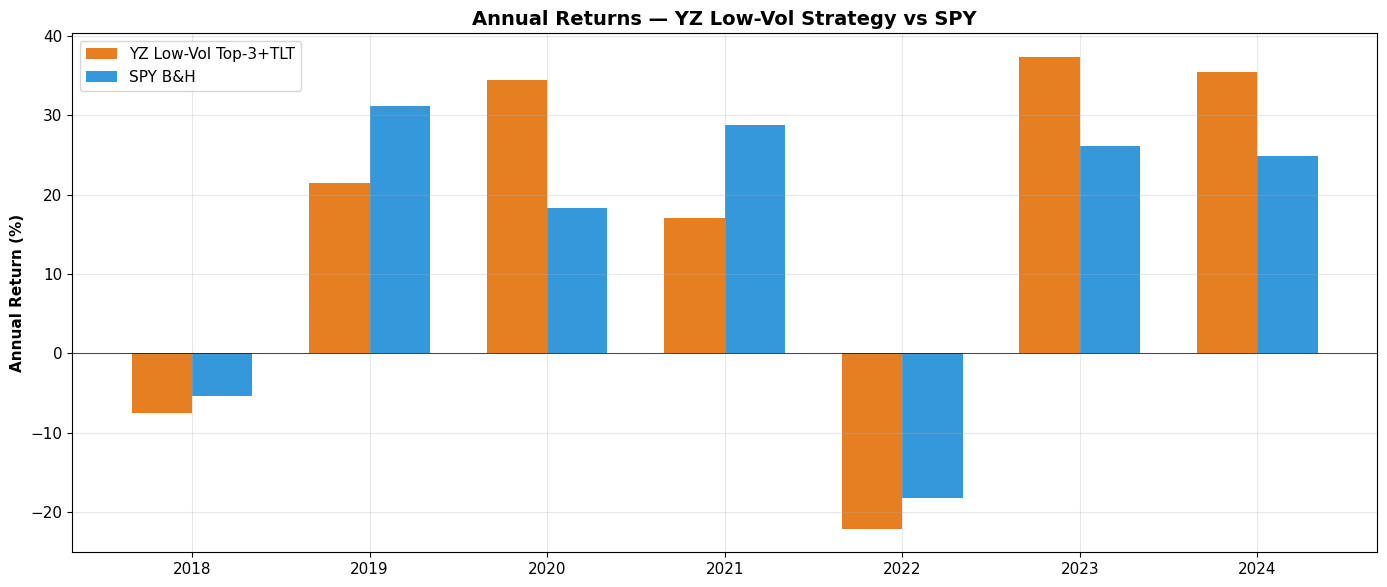

In [13]:
# ============================================================
#  ANNUAL RETURNS COMPARISON
# ============================================================

ann_s   = port_ret.resample('YE').apply(lambda x: (1+x).prod()-1)
ann_spy = spy_ret.resample('YE').apply(lambda x: (1+x).prod()-1)
yrs = ann_s.index.year; x = np.arange(len(yrs))

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - 0.17, ann_s.values * 100, 0.34,
       label=f'YZ Low-Vol Top-{TOP_N}+TLT', color='#e67e22')
ax.bar(x + 0.17, ann_spy.values * 100, 0.34,
       label='SPY B&H', color='#3498db')
ax.set_xticks(x); ax.set_xticklabels(yrs)
ax.set_ylabel('Annual Return (%)'); ax.axhline(0, color='black', lw=0.5)
ax.set_title('Annual Returns — YZ Low-Vol Strategy vs SPY', fontsize=14)
ax.legend(); plt.tight_layout(); plt.show()

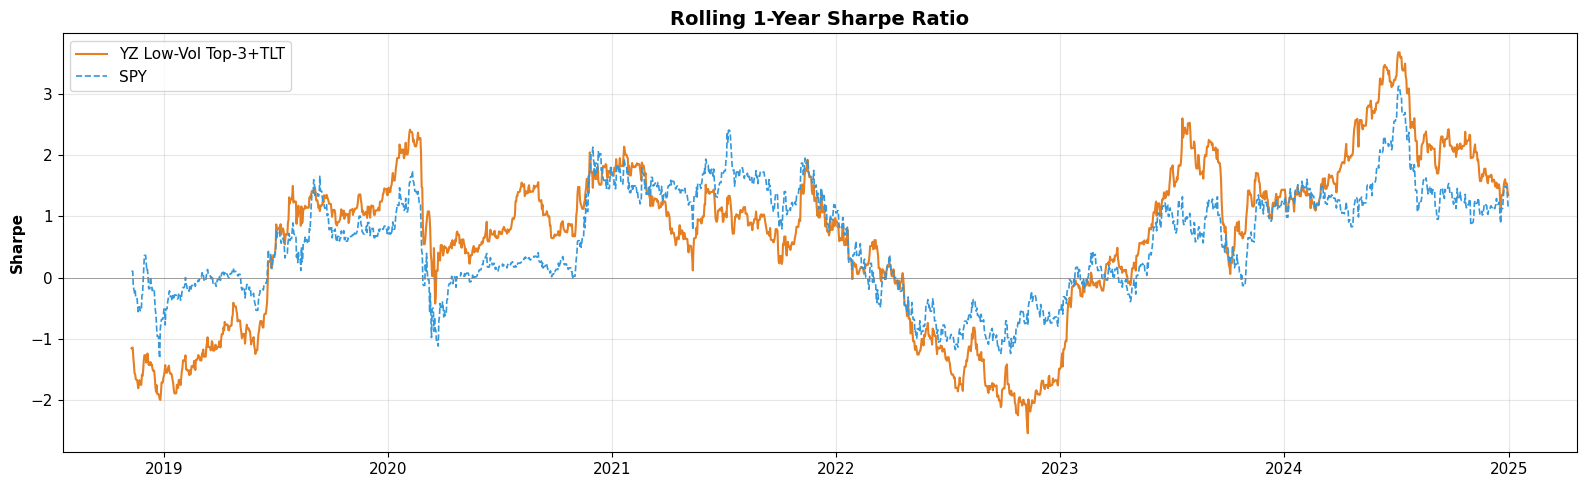

In [14]:
# ============================================================
#  ROLLING 1-YEAR SHARPE RATIO
# ============================================================

rfd = (1.04) ** (1/252) - 1  # daily risk-free rate (4% annual)
rs_s   = (port_ret.rolling(252).mean() - rfd) / port_ret.rolling(252).std() * np.sqrt(252)
rs_spy = (spy_ret.rolling(252).mean() - rfd) / spy_ret.rolling(252).std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(rs_s.index, rs_s, color='#e67e22', lw=1.5,
        label=f'YZ Low-Vol Top-{TOP_N}+TLT')
ax.plot(rs_spy.index, rs_spy, color='#3498db', lw=1.2, ls='--', label='SPY')
ax.axhline(0, color='gray', lw=0.5)
ax.set_title('Rolling 1-Year Sharpe Ratio', fontsize=14)
ax.set_ylabel('Sharpe'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Rebalance Log

In [15]:
# ============================================================
#  REBALANCE LOG — LAST 20
# ============================================================

print(f'Last 20 of {len(rebal_log)} rebalances:\n')
print(f'{"Date":>12} | {"Risk-On":>8} | {"TLT Wt":>7} | Selected Assets (YZ Vol → Weight)')
print('=' * 85)
for r in rebal_log[-20:]:
    d = r['date'].strftime('%Y-%m-%d')
    parts = []
    for t in r['selected']:
        vol = r['yz_vols'][t]
        wt  = r['weights'].get(t, 0)
        parts.append(f"{t}({vol:.0%}→{wt:.0%})")
    a = ', '.join(parts)
    if not a:
        a = '(none — 100% TLT)'
    print(f'{d:>12} | {r["n_selected"]:>8} | {r["tlt_weight"]:>7.1%} | {a}')

Last 20 of 250 rebalances:

        Date |  Risk-On |  TLT Wt | Selected Assets (YZ Vol → Weight)
  2024-06-19 |        3 |    0.0% | SPY(12%→40%), GLD(15%→30%), QQQ(15%→30%)
  2024-06-29 |        3 |    0.0% | SPY(11%→41%), QQQ(15%→31%), GLD(16%→28%)
  2024-07-09 |        3 |    0.0% | SPY(9%→42%), QQQ(13%→30%), GLD(13%→28%)
  2024-07-19 |        3 |    0.0% | SPY(10%→41%), GLD(14%→31%), QQQ(15%→28%)
  2024-07-29 |        3 |   -0.0% | SPY(12%→38%), GLD(14%→35%), QQQ(18%→27%)
  2024-08-08 |        3 |    0.0% | GLD(18%→38%), SPY(21%→32%), XLE(23%→30%)
  2024-08-18 |        3 |    0.0% | GLD(18%→38%), SPY(21%→32%), XLE(23%→30%)
  2024-08-28 |        3 |    0.0% | GLD(18%→38%), SPY(21%→32%), XLE(22%→30%)
  2024-09-07 |        3 |    0.0% | SPY(14%→37%), GLD(14%→36%), QQQ(19%→27%)
  2024-09-17 |        3 |    0.0% | GLD(13%→41%), SPY(16%→33%), XLE(21%→25%)
  2024-09-27 |        3 |   -0.0% | GLD(12%→43%), SPY(16%→33%), QQQ(22%→24%)
  2024-10-07 |        3 |    0.0% | GLD(12%→42%), SPY(15

## 7. Key Takeaways

### Lookahead Bias Prevention

This backtest is **lookahead-free**:
- YZ vol at day $t$ is computed from OHLC $[t-30, t]$ — all known at close of day $t$
- Signal is **shifted by 1 day** (`yz_df = yz_raw.shift(1)`)
- On rebalance day $t$, the backtest sees YZ vol from day $t-1$
- Weights are applied to day $t$'s return (close $t-1$ → close $t$)

### Why Yang-Zhang for This Model?

| Advantage | Impact on Model |
|-----------|----------------|
| Uses OHLC (not just close) | More accurate vol → better asset ranking |
| Captures overnight gaps | Correctly penalizes gappy assets (BTC, TSLA) |
| ~14x efficiency | Stable estimates with only 30-day window |
| Drift-independent | No bias when stocks trend strongly |

### Low-Vol Anomaly

The strategy exploits one of the most robust anomalies in finance:
- **Low-vol assets deliver higher Sharpe ratios** than high-vol assets
- This is counter-intuitive (more risk ≠ more reward on a risk-adjusted basis)
- Yang-Zhang is the ideal vol estimator for this because it's the **most precise** daily estimator available

### TLT Risk-Off Mechanism
- Acts as **flight-to-quality** during periods when all assets are volatile (vol > 30%)
- Bonds often rally during equity drawdowns → natural hedging
- Partial TLT allocation (1/3, 2/3) allows gradual risk scaling

### Potential Improvements

| Enhancement | Description |
|-------------|-------------|
| Momentum overlay | Combine low-vol with trailing returns for timing |
| YZ decomposition filter | Penalize assets with high overnight gap ratio |
| Walk-forward vol threshold | Optimize max_vol dynamically |
| Transaction costs | Add slippage + commission modeling |
| Multi-window YZ | Average vol across 10d, 30d, 60d windows |
| Long/short variant | Short highest-vol assets (most risky) |